## Goal

Understand the building blocks — generators, selectors, DGPs, and pipelines — before going through the per-deficit tutorials.

## 1. Where generators live: the module structure

Generators are grouped first by **modality** (`tabular_data`, `time_series`, `text`, `image`, `graph`, `geolocated_data`), then by **deficit family** (`outliers`, `noise`, `drift`, `missingness`, `imbalance`). Every family is a Python package of modules, and every generator is a **class** whose name ends in `Generator`.

## 2. Instantiate a generator

A generator is a plain Python class.
Each generator takes a `numpy.random.Generator` at construction:

```python
gen = SomeGenerator(random_generator=default_rng(seed))
```


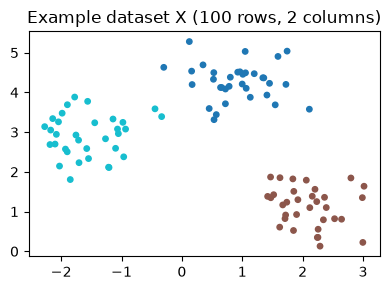

In [1]:
# Setup: imports and a small example dataset used throughout the notebook
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import scipy.stats

from numpy.random import default_rng
from sklearn.datasets import make_blobs

X, cls = make_blobs(n_samples=100, centers=3, cluster_std=0.5, random_state=0)

plt.figure(figsize=(4, 3))
plt.scatter(X[:, 0], X[:, 1], c=cls, cmap="tab10", s=15)
plt.title("Example dataset X (100 rows, 2 columns)")
plt.tight_layout()
plt.show()


### Adding rows, exemplified: outliers

This example adds 10 outliers to `X`. Note what happens to the
shape: the outliers are **appended** as new rows, so `Xt` is bigger
than `X`.


In [2]:
from badgers.generators.tabular_data.outliers.distribution_sampling import (
    ZScoreSamplingGenerator,
)

gen = ZScoreSamplingGenerator(random_generator=default_rng(0))

Xt, _ = gen.generate(X.copy(), None, n_outliers=10)   # X.copy(): keep the original untouched (generators mutate in place)
print('outliers:', X.shape, '->', Xt.shape)


outliers: (100, 2) -> (110, 2)


### Deficit labels

Some generators save which rows have been modified and expose this information through a dedicated getter — for outliers,
`get_outliers_labels()`:


In [3]:
labels = gen.get_outliers_labels()      # bool array: True = outlier row
print('labels:', labels.dtype, 'length', len(labels), '| outlier rows:', int(labels.sum()))
print('first rows are original:', not labels[:len(X)].any())
print('last rows are outliers:', labels[len(X):].all())


labels: bool length 110 | outlier rows: 10
first rows are original: True
last rows are outliers: True


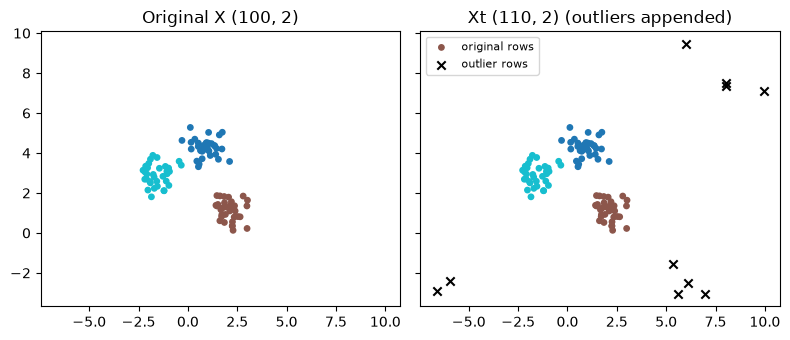

In [4]:
# Visualize: the 10 outlier rows are appended AFTER the original rows
labels = gen.get_outliers_labels()

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)
axes[0].scatter(X[:, 0], X[:, 1], c=cls, cmap="tab10", s=15)
axes[0].set_title(f"Original X {X.shape}")
axes[1].scatter(Xt[:len(X), 0], Xt[:len(X), 1], c=cls, cmap="tab10", s=15, label="original rows")
axes[1].scatter(Xt[len(X):, 0], Xt[len(X):, 1], marker="x", c="black", label="outlier rows")
axes[1].set_title(f"Xt {Xt.shape} (outliers appended)")
axes[1].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


## 4. Shape rules: what happens to `Xt`

The shape of `Xt` depends on the deficit family — there are exactly
three modes:

| Mode  | Effect on shape |
|---|---|
| **Adding rows**  | `Xt` is *larger* than `X` (deficit rows appended) |
| **Changing values**  | `Xt` has the *same shape* as `X` (existing values are changed) |
| **Removing rows**  | `Xt` is *smaller* than `X` (affected rows are dropped) |



### Changing values, exemplified: noise

Additive noise replaces the existing values in place, so
100 rows stay 100 rows:


In [5]:
from badgers.generators.tabular_data.noise import AdditiveNoiseGenerator

gen = AdditiveNoiseGenerator(random_generator=default_rng(0))
Xt, _ = gen.generate(X.copy(), None, distribution=scipy.stats.norm(scale=0.5))  # y=None (deprecated slot)
print('noise (values changed, same shape):', X.shape, '->', Xt.shape)


noise (values changed, same shape): (100, 2) -> (100, 2)


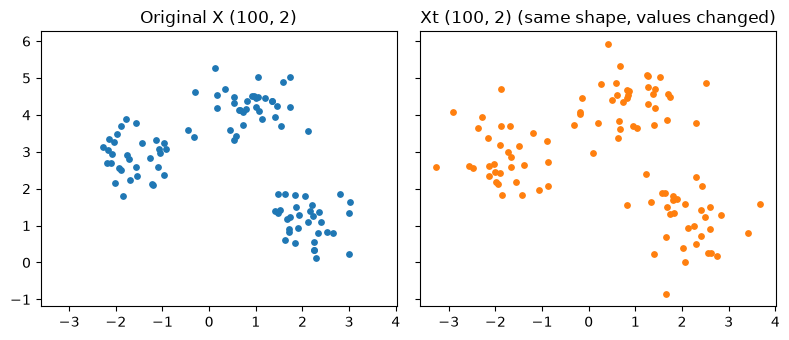

In [6]:
# Visualize: values changed — same rows, same shape; each point is displaced a little
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)
axes[0].scatter(X[:, 0], X[:, 1], s=15)
axes[0].set_title(f"Original X {X.shape}")
axes[1].scatter(Xt[:, 0], Xt[:, 1], s=15, c="C1")
axes[1].set_title(f"Xt {Xt.shape} (same shape, values changed)")
plt.tight_layout()
plt.show()


### Removing rows, exemplified: imbalance

An imbalance generator *removes* the
rows affected by the deficit. The only thing it needs to know is
*which rows* — that decision is packaged in a `selector` (a boolean
mask per column). Selectors are their own concept and get a full
section below (section 5); here we just use one preset so the shape
rule is visible: about half of the 100 rows are removed.


In [7]:
from badgers.generators.tabular_data.imbalance.imbalance import RandomSamplingTargetsGenerator
from badgers.core.selectors import BernoulliSelector

gen = RandomSamplingTargetsGenerator(random_generator=default_rng(1))
selector = BernoulliSelector(['f0'], rate=0.5, rng=default_rng(2))

Xt, yt = gen.generate(X.copy(), None, selector=selector)
print('imbalance (rows removed):', X.shape, '->', Xt.shape)


imbalance (rows removed): (100, 2) -> (49, 2)


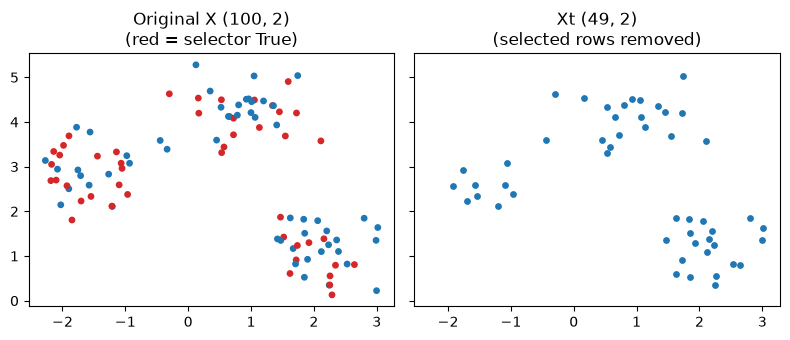

In [8]:
# Visualize: rows removed — the rows marked True by the selector are dropped
mask = selector(X, None)["f0"]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)
axes[0].scatter(X[:, 0], X[:, 1], c=np.where(mask, "C3", "C0"), s=15)
axes[0].set_title(f"Original X {X.shape}\n(red = selector True)")
axes[1].scatter(Xt[:, 0], Xt[:, 1], s=15, c="C0")
axes[1].set_title(f"Xt {Xt.shape}\n(selected rows removed)")
plt.tight_layout()
plt.show()


## 5. Selectors: which rows get the deficit

Generators (drift, missingness, noise, imbalance, ...) accept a **selector**: an object that decides *which rows receive the deficit*.

### The contract

```python
values = selector(X, y)   # -> {variable: array}
```

Per variable (column) the returned array is either:

* a **boolean mask** — `True` = the deficit is applied to that row (deterministic), or
* a **float score in [0, 1]** — the *probability* that the deficit is applied to that row (1.0 = definitely, 0.0 = never).

### The presets

Badgers ships selectors (see `badgers.core.selectors`):


BernoulliSelector mask dtype: bool | affected rows: 37
TopQuantileSelector mask dtype: bool | affected rows: 20


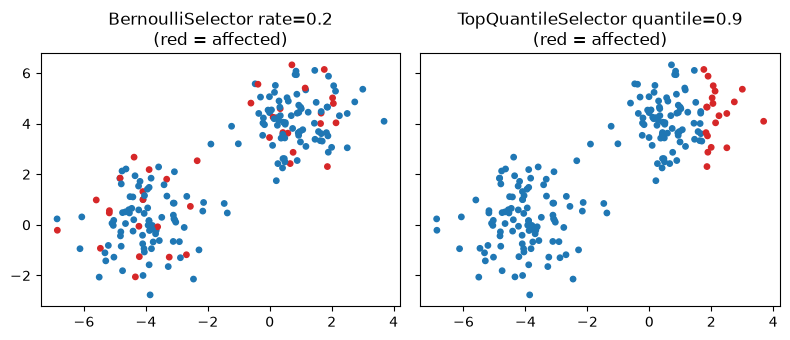

In [9]:
from badgers.core.selectors import BernoulliSelector, TopQuantileSelector

X_raw, _ = make_blobs(n_samples=200, centers=2, random_state=3)

# BernoulliSelector realizes its rng at call time and returns a
# boolean mask (True = affected row).
selector = BernoulliSelector(['f0'], rate=0.2, rng=default_rng(0))
mask = selector(X_raw, y=None)['f0']
print('BernoulliSelector mask dtype:', mask.dtype, '| affected rows:', int(mask.sum()))

# A deterministic rule: rows in the top 10% of f0.
selector = TopQuantileSelector(['f0'], column_mapping={'f0': 0}, quantile=0.9)
mask = selector(X_raw, y=None)['f0']
print('TopQuantileSelector mask dtype:', mask.dtype, '| affected rows:', int(mask.sum()))

# Visualize both masks side by side
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)
mask_b = BernoulliSelector(['f0'], rate=0.2, rng=default_rng(0))(X_raw, None)['f0']
mask_q = TopQuantileSelector(['f0'], column_mapping={'f0': 0}, quantile=0.9)(X_raw, None)['f0']
axes[0].scatter(X_raw[:, 0], X_raw[:, 1], c=np.where(mask_b, "C3", "C0"), s=15)
axes[0].set_title("BernoulliSelector rate=0.2\n(red = affected)")
axes[1].scatter(X_raw[:, 0], X_raw[:, 1], c=np.where(mask_q, "C3", "C0"), s=15)
axes[1].set_title("TopQuantileSelector quantile=0.9\n(red = affected)")
plt.tight_layout()
plt.show()


## 6. Data-generating processes (DGP) and structural causal models (SCM)

Some generators use a **structural causal model (SCM)** to represent the underlying data-generating process (DGP). An SCM encodes *how the columns come about*, not just what they look like: each column is generated from its causal parents plus noise, following the edges of a causal graph. In badgers a DGP is an object that bundles:

* a `networkx.DiGraph` describing the causal structure (an edge `A -> B` means A is a cause of B),
* a `column_mapping` from node names to column positions in `X`, and
* per-node **causal mechanisms** estimated from the data (e.g., a linear regression of the child on its parents plus a noise term).

This is what makes causal generators different from plain value edits: they **intervene** on a node (fix its values, `do(B = v)`), then **sample** — i.e. recompute that node's children and all their descendants from the SCM, so the whole downstream part of the data stays consistent with the causal structure.

### Functions:

```python
dgp = GcmSCMDGP(scm).fit(X)                  # fit mechanisms (scm: a dowhy-gcm StructuralCausalModel)
Xs = dgp.sample(rng, n)                      # sample fresh data from the SCM
Xi = dgp.intervene(X.copy(), ['B'], [values], rng=rng)  # do(B = ...), descendants recomputed
```

### Backends:

The shipped backends are two SCM adapters in `badgers.core.dgp.backends`:
`GcmSCMDGP` wraps a `dowhy.gcm.StructuralCausalModel` (extra `badgers[dowhy]`)
and `PyMCSCMDGP` wraps a PyMC `pm.Model` (extra `badgers[pymc]`) — build the
SCM with the wrapped library's own API, then hand it over. There is no
default backend: causal generators require an explicit `dgp=`.
See the dev notebook *Using DGPs* for the two adapters in action.

In [10]:
import networkx as nx
import dowhy.gcm as gcm
from badgers.core.dgp.backends import GcmSCMDGP

# DGP definition (linear model with additive noise):
# X_0 = Normal distribution mu=0, sigma=1
# X_1 = 2 * X_0 + noise
# X_2 = 0.5 * X_1 + noise

graph = nx.DiGraph([('A', 'B'), ('B', 'C')])
column_mapping = {'A': 0, 'B': 1, 'C': 2}

rng = default_rng(0)
X_raw = np.zeros((500, 3))
X_raw[:, 0] = rng.normal(size=500)
X_raw[:, 1] = 2.0 * X_raw[:, 0] + rng.normal(scale=0.1, size=500)
X_raw[:, 2] = 0.5 * X_raw[:, 1] + rng.normal(scale=0.1, size=500)

scm = gcm.StructuralCausalModel(graph)
for node in graph.nodes:
    if not list(graph.predecessors(node)):
        scm.set_causal_mechanism(node, gcm.EmpiricalDistribution())
    else:
        scm.set_causal_mechanism(node, gcm.AdditiveNoiseModel(
            prediction_model=gcm.ml.create_linear_regressor()))

dgp = GcmSCMDGP(scm, column_mapping).fit(X_raw)

# sample fresh data from the fitted DGP (signature: sample(rng, n))
Xs = dgp.sample(default_rng(1), 10)
print('sampled shape:', Xs.shape)

# intervene in place: pass a copy, fix the values in B (all = 10), recompute C downstream
Xi = dgp.intervene(X_raw.copy(), ['B'], [np.full(500, 10.0)], rng=default_rng(2))
print('B pinned:', np.allclose(Xi[:, 1], 10.0))
print('C propagated (B=10 -> C~5):', np.allclose(Xi[:, 2], 5.0, atol=0.5))

C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fitting causal mechanism of node C: 100%|██████████████████████████████████| 3/3 [00:00<00:00, 198.33it/s]

sampled shape: (10, 3)
B pinned: True
C propagated (B=10 -> C~5): True


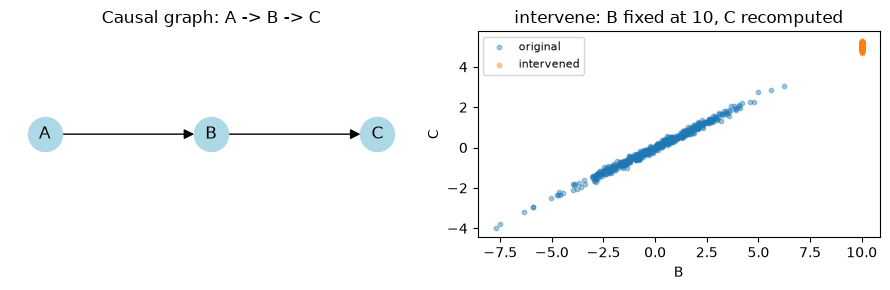

In [11]:
# Visualize: the chain A -> B -> C, and the intervention do(B = 10)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))

pos = {"A": (0, 0), "B": (1, 0), "C": (2, 0)}
nx.draw(graph, pos, ax=axes[0], node_color="lightblue", node_size=600, arrowsize=15)
nx.draw_networkx_labels(graph, pos, ax=axes[0])
axes[0].set_title("Causal graph: A -> B -> C")
axes[0].axis("off")

axes[1].scatter(X_raw[:, 1], X_raw[:, 2], s=10, alpha=0.4, label="original")
axes[1].scatter(Xi[:, 1], Xi[:, 2], s=10, alpha=0.4, label="intervened")
axes[1].set_xlabel("B")
axes[1].set_ylabel("C")
axes[1].set_title("intervene: B fixed at 10, C recomputed")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


## 7. Pipelines: chaining deficits

Deficits compose. A `Pipeline` takes a dict of generators (the keys
are step names) and applies them in order, passing each output to the
next step. Per-step parameters are passed at `generate()` time keyed
by the step name:


In [12]:
from badgers.core.pipeline import Pipeline
from badgers.generators.tabular_data.noise import AdditiveNoiseGenerator
from badgers.generators.tabular_data.outliers.distribution_sampling import HypersphereSamplingGenerator

pipeline = Pipeline({
    "noise": AdditiveNoiseGenerator(random_generator=default_rng(3)),
    "outliers": HypersphereSamplingGenerator(random_generator=default_rng(4)),
})
Xt, _ = pipeline.generate(X.copy(), None, params={
    "noise": {"distribution": scipy.stats.norm(scale=0.5)},
    "outliers": {"n_outliers": 10},
})
print('pipeline output:', X.shape, '->', Xt.shape)


pipeline output: (100, 2) -> (110, 2)


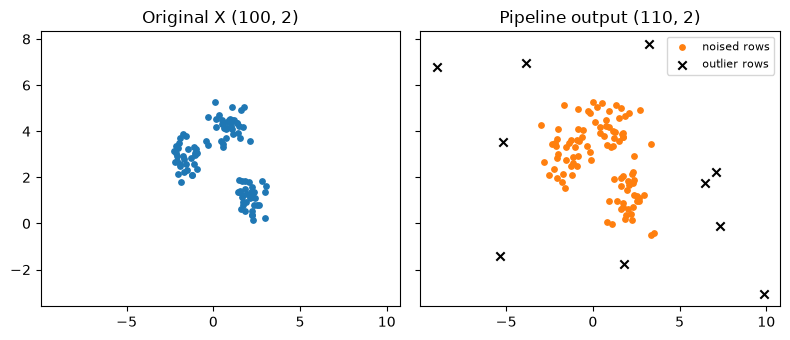

In [13]:
# Visualize: the pipeline output — noisy original rows + appended outliers
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)
axes[0].scatter(X[:, 0], X[:, 1], s=15)
axes[0].set_title(f"Original X {X.shape}")
axes[1].scatter(Xt[:len(X), 0], Xt[:len(X), 1], s=15, c="C1", label="noised rows")
axes[1].scatter(Xt[len(X):, 0], Xt[len(X):, 1], marker="x", c="black", label="outlier rows")
axes[1].set_title(f"Pipeline output {Xt.shape}")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


## 8. Randomness


Badgers generators **never touch global random state**. The sequence of random numbers they use is the one supplied at construction, so:

* same seed => identical outputs, bit for bit;
* the stream is owned by the caller — create one generator and pass
  it to several generators to keep a single reproducible stream.


In [14]:
from numpy.random import default_rng
from badgers.generators.tabular_data.outliers.distribution_sampling import ZScoreSamplingGenerator

gen = ZScoreSamplingGenerator(random_generator=default_rng(0))
print(gen)


### Same seed, same output

Two generators built from the same seed
produce bit-identical results — the reproducibility contract in action:


In [15]:
import numpy as np
from sklearn.datasets import make_blobs

X_ex, _ = make_blobs(n_samples=100, centers=2, random_state=2)   # known-good data

g1 = ZScoreSamplingGenerator(random_generator=default_rng(42))
g2 = ZScoreSamplingGenerator(random_generator=default_rng(42))
Xt1, _ = g1.generate(X_ex, None, n_outliers=10)
Xt2, _ = g2.generate(X_ex, None, n_outliers=10)
print('same seed -> identical output:', np.array_equal(Xt1, Xt2))

g3 = ZScoreSamplingGenerator(random_generator=default_rng(7))
Xt3, _ = g3.generate(X_ex, None, n_outliers=10)
print('different seed -> different output:', not np.array_equal(Xt1, Xt3))


same seed -> identical output: True
different seed -> different output: True


## 9. Where to go next

### Tabular data

| Goal | Tutorial |
|---|---|
| Add outliers to tabular data | [Generating Outliers](../../tabular-data/Outliers/) (Part A) |
| Add noise | [Generating Noise](../../tabular-data/Noise/) (Part A) |
| Introduce missing values | [Generating Missing Data](../../tabular-data/Missingness/) (Part A) |
| Generate class imbalance | [Generating Imbalanced Data](../../tabular-data/Imbalance/) (Part A) |
| Shift data over time (drift) | [Generating Drift](../../tabular-data/Drift/) (Part A) |
| Make deficits structurally consistent (with a causal graph) | each tabular tutorial, **Part B** — Acting on the DGP |

### Beyond tabular data

| Goal | Tutorial |
|---|---|
| Corrupt text data (typos) | [Generating Typos](../../text/Typos-Text/) |
| Corrupt time series | the *Time Series Data* tutorials, e.g. [Generating Point Outliers](../../time-series/Outliers-Time-Series/) |

### Going further

| Goal | Tutorial |
|---|---|
| Chain several deficits | [Chaining Generators](../../Pipeline-Tabular-Data/) |
| Build custom generators | [Creating Tabular Generators](../../dev/Create-New-Tabular-Generators/) |
| Build custom selectors | [Creating Selectors](../../dev/Create-New-Selectors/) |
| Use the bundled causal backends (dowhy-gcm / pymc) | [Using DGPs](../../dev/Using-DGPs/) |

## Takeaways

- Generators are instantiated with an rng and called via `generate(X, y, **params)`.
- Shape rules: appending (outliers), shape-preserving (noise, missingness), row-removing (imbalance).
- Selectors decide which rows are affected; DGPs model the data-generating process; pipelines compose generators.